In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [69]:
file_path = r"C:\Users\advvi\Downloads\Data Analyst Assigment\Data Analyst Assigment\noshowappointments - noshowappointments (3).csv"
df = pd.read_csv(file_path)

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62.0,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62.0,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8.0,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0,1,1,0,0,0,No


In [70]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

df.info()

df.describe()

Dataset Shape: (110527, 14)

Column Names:
Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110520 non-null  float64
 6   Neighbourhood   110520 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handca

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110520.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.089115,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110409,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.920000e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [71]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               7
Neighbourhood     7
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Duplicate Records: 0


In [72]:
df = df.drop_duplicates()

df['Age'] = df['Age'].mask(df['Age'] < 0)

df['Age'] = df['Age'].fillna(df['Age'].median())

df['Neighbourhood'] = df['Neighbourhood'].fillna('Unknown')

df['Gender'] = df['Gender'].replace({
    'Fml': 'F',
    'Femal': 'F',
    'Female': 'F',
    'Fe': 'F',
    'Ml': 'M',
    'Mal': 'M',
    'Male': 'M',
    'Othr': 'O',
    'Other': 'O'
})

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

df.head()

Missing Values After Cleaning:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Cleaned Dataset Shape: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62.0,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62.0,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8.0,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56.0,JARDIM DA PENHA,0,1,1,0,0,0,No


In [73]:
total_records = len(df)

print("Total Appointments:", total_records)

status_count = df['No-show'].value_counts()

print("\nAppointment Status:")
print(status_count)

neighbourhood_count = df['Neighbourhood'].value_counts()

print("\nNeighbourhood-wise Appointments:")
print(neighbourhood_count)

Total Appointments: 110527

Appointment Status:
No-show
No     88208
Yes    22319
Name: count, dtype: int64

Neighbourhood-wise Appointments:
Neighbourhood
JARDIM CAMBURI                 7717
MARIA ORTIZ                    5805
RESISTÊNCIA                    4429
JARDIM DA PENHA                3876
ITARARÉ                        3514
                               ... 
ILHA DO FRADE                    10
AEROPORTO                         8
Unknown                           7
ILHAS OCEÂNICAS DE TRINDADE       2
PARQUE INDUSTRIAL                 1
Name: count, Length: 82, dtype: int64


In [74]:
status_percentage = df['No-show'].value_counts(normalize=True) * 100

print("Appointment Status Percentage:")

print(status_percentage.round(2))

status_summary = pd.DataFrame({
    'Appointment Count': status_count,
    'Percentage': status_percentage.round(2)
})

print("\nStatus Summary:")
display(status_summary)

Appointment Status Percentage:
No-show
No     79.81
Yes    20.19
Name: proportion, dtype: float64

Status Summary:


,Appointment Count,Percentage
No-show,,
No,88208,79.81
Yes,22319,20.19


In [75]:
result = pd.crosstab(df['Neighbourhood'], df['No-show'])

result['Total'] = result['Yes'] + result['No']

result['Percentage'] = result['Yes'] / result['Total'] * 100

result = result[result['Total'] >= 500]

display(result.sort_values('Percentage', ascending=False).head(5))

No-show,No,Yes,Total,Percentage
Neighbourhood,,,,
SANTOS DUMONT,907,369,1276,28.918495
SANTA CLARA,372,134,506,26.482213
ITARARÉ,2591,923,3514,26.266363
JESUS DE NAZARETH,2157,696,2853,24.395373
ILHA DO PRÍNCIPE,1734,532,2266,23.477493


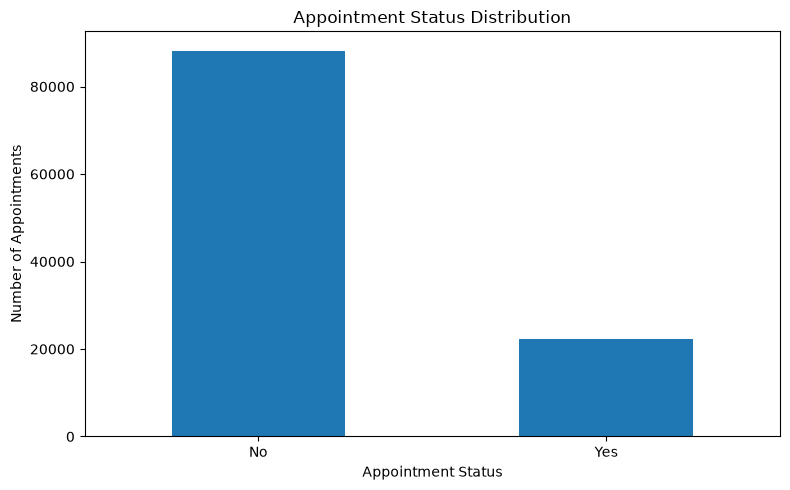

In [76]:
plt.figure(figsize=(8, 5))

status_count.plot(kind='bar')

plt.title('Appointment Status Distribution')
plt.xlabel('Appointment Status')
plt.ylabel('Number of Appointments')

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

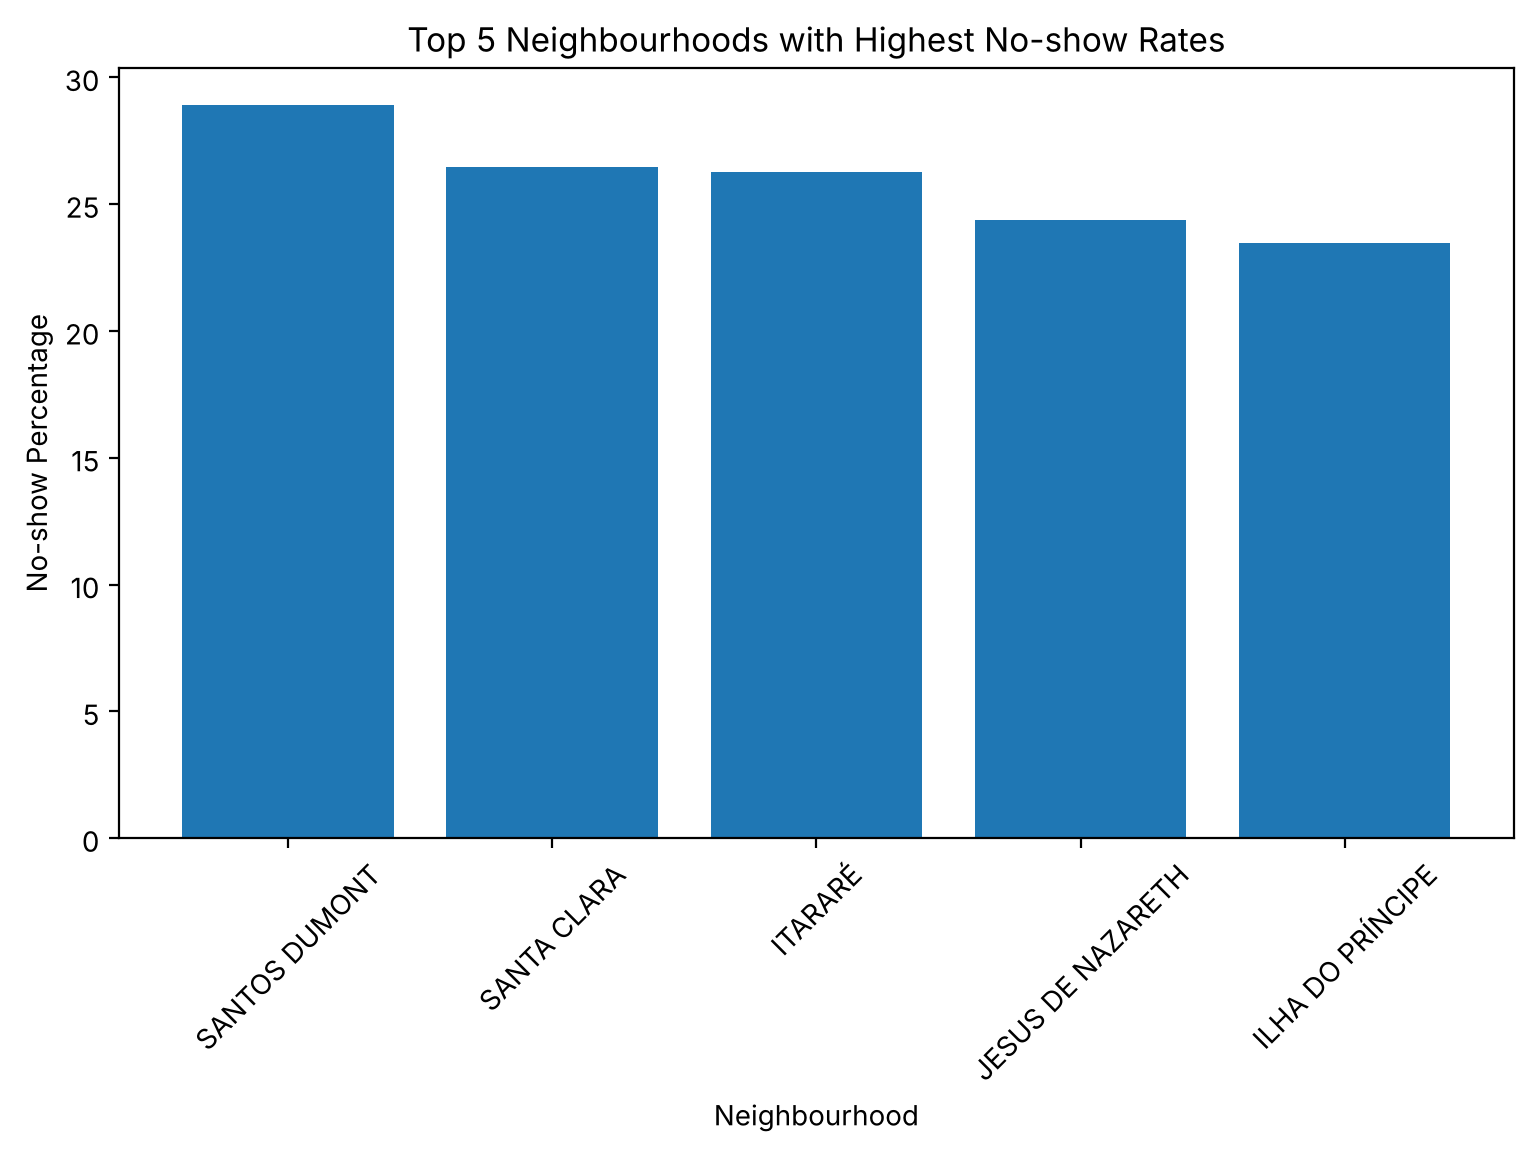

In [77]:
top_5 = result.sort_values('Percentage', ascending=False).head(5)

plt.figure(figsize=(9,5))
plt.bar(top_5.index, top_5['Percentage'])

plt.title('Top 5 Neighbourhoods with Highest No-show Rates')
plt.xlabel('Neighbourhood')
plt.ylabel('No-show Percentage')
plt.xticks(rotation=45)

plt.show()

In [78]:
total_records = len(df)

highest_appointments = df['Neighbourhood'].value_counts().idxmax()

highest_no_show = result.sort_values(
    'Percentage', ascending=False
).index[0]

attended = status_percentage['No']
no_show = status_percentage['Yes']

print("BUSINESS OBSERVATIONS")

print("1. Total appointments:", total_records)

print("2. Patients attended:", round(attended, 2), "%")

print("3. Patients did not attend:", round(no_show, 2), "%")

print("4. Highest appointments:", highest_appointments)

print("5. Highest no-show neighbourhood:", highest_no_show)

BUSINESS OBSERVATIONS
1. Total appointments: 110527
2. Patients attended: 79.81 %
3. Patients did not attend: 20.19 %
4. Highest appointments: JARDIM CAMBURI
5. Highest no-show neighbourhood: SANTOS DUMONT


In [80]:
import openpyxl
print("Openpyxl installed successfully!")

Openpyxl installed successfully!


In [ ]:
import os
import pandas as pd

output_path = r"C:\Users\advvi\Downloads\Data Analyst Assigment\Data Analyst Assigment"

with pd.ExcelWriter(os.path.join(output_path, "Hospital_Appointment_Analysis.xlsx")) as writer:

    df.to_excel(writer, sheet_name="Cleaned Data", index=False)
    status_summary.to_excel(writer, sheet_name="Status Summary")
    result.to_excel(writer, sheet_name="Neighbourhood Analysis")

print("Excel file saved successfully!")

In [ ]:
os.startfile(os.path.join(output_path, "Hospital_Appointment_Analysis.xlsx"))